# Day-3: Filters demo

Hands-on companion to [README.md](README.md) (sections 6 and 7). In this notebook we:

1. Load a colour image with **matplotlib** and with **OpenCV**, and see why the colours differ.
2. Split a colour image into its **R, G, B channels**.
3. Look at the **Sobel filter** for vertical and horizontal edges.
4. Build a tiny image from a matrix and write **convolution from scratch**.
5. Run the same Sobel filters on a real photo and check our function against `cv2.filter2D`.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
from pathlib import Path

## 1. Load an image

The notebook was first written in Google Colab with an uploaded `/content/download.jpg`. Locally we fall back to the car photo from Day-2, so the same notebook runs in both places.

In [2]:
colab_path = Path("/content/download.jpg")
img_path = str(colab_path) if colab_path.exists() else "../Day-2/data/images.jpg"
print("Using:", img_path)

Using: ../Day-2/data/images.jpg


### 1.1 With matplotlib

`mpimg.imread` returns the pixels in **RGB** order, which is what `plt.imshow` expects, so the colours look right straight away.

The shape is `(height, width, channels)`: 3 channels = red, green, blue.

shape: (452, 678, 3)
dtype: uint8 | min: 0 | max: 255
top-left pixel (R, G, B): [28 18  8]


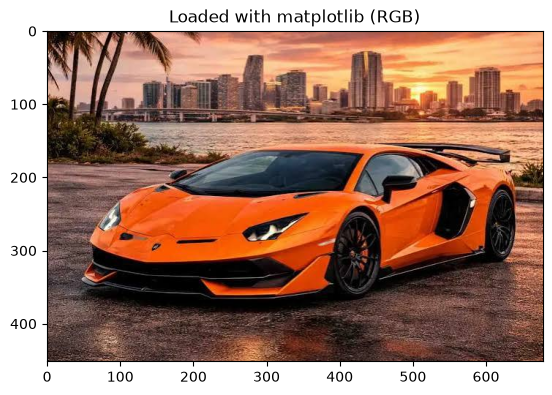

In [3]:
car1 = mpimg.imread(img_path)

print("shape:", car1.shape)
print("dtype:", car1.dtype, "| min:", car1.min(), "| max:", car1.max())
print("top-left pixel (R, G, B):", car1[0, 0])

plt.imshow(car1)
plt.title("Loaded with matplotlib (RGB)")
plt.show()

### 1.2 With OpenCV

`cv2.imread` returns the same numbers but in **BGR** order. If we show it with matplotlib directly, red and blue swap places, so the red/orange car turns blue.

shape: (452, 678, 3)
top-left pixel (B, G, R): [ 8 18 28]


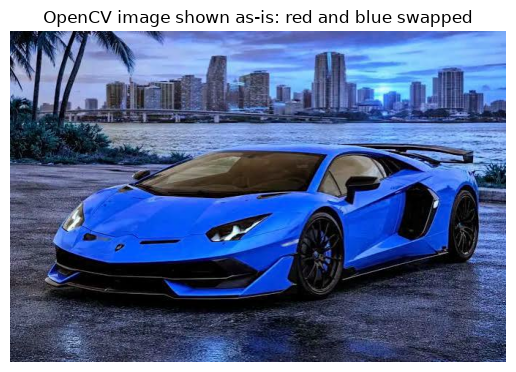

In [4]:
car1_cv2 = cv2.imread(img_path)          # BGR
print("shape:", car1_cv2.shape)
print("top-left pixel (B, G, R):", car1_cv2[0, 0])

plt.imshow(car1_cv2)
plt.title("OpenCV image shown as-is: red and blue swapped")
plt.axis("off")
plt.show()

The fix is one line: `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`. A small helper so we don't repeat it:

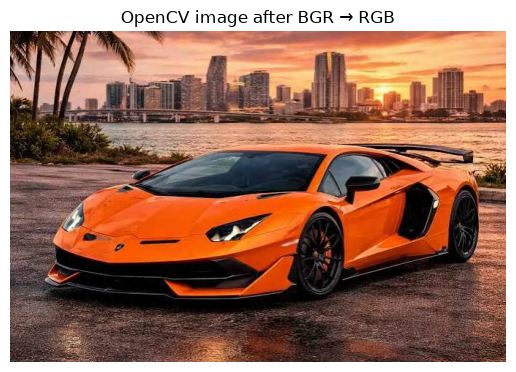

In [5]:
def show_bgr_image(image_bgr, title=None):
    # Convert a BGR (OpenCV) image to RGB, show it, and return the RGB copy.
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    plt.imshow(image_rgb)
    if title:
        plt.title(title)
    plt.axis("off")
    plt.show()
    return image_rgb


car1_rgb = show_bgr_image(car1_cv2, "OpenCV image after BGR → RGB")

### 1.3 Grayscale

A grayscale image has **one** channel: just brightness, 0 (black) to 255 (white). Edge filters like Sobel work on this single channel.

gray shape: (452, 678)


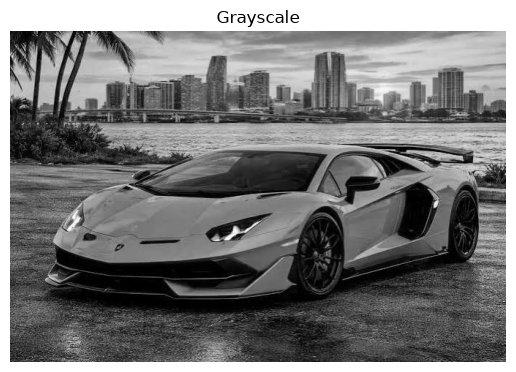

In [6]:
car1_gray = cv2.cvtColor(car1_cv2, cv2.COLOR_BGR2GRAY)
print("gray shape:", car1_gray.shape)    # no channel dimension any more

plt.imshow(car1_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")
plt.show()

## 2. Understanding the composition of colour images

A colour image is really **three grayscale images stacked on top of each other**, one each for red, green and blue. Each pixel is a mix of the three values.

- `img[:, :, 0]` → red channel
- `img[:, :, 1]` → green channel
- `img[:, :, 2]` → blue channel

(This is for an RGB image. For an OpenCV BGR image, index 0 is blue.)

In each channel plot, a darker colour means more of that colour at that pixel.

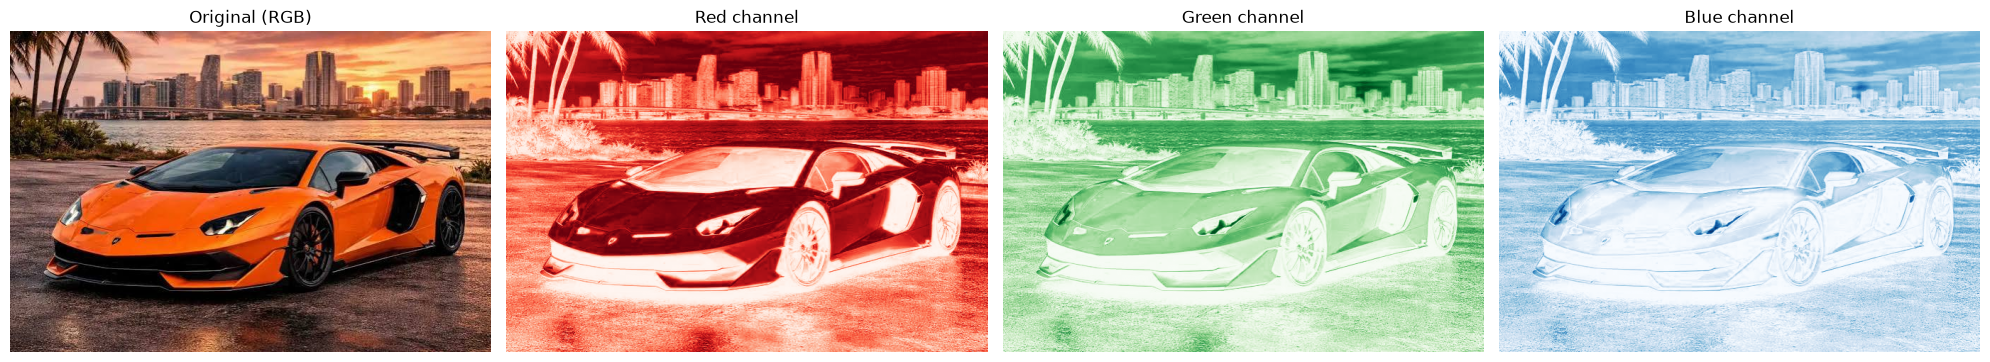

In [7]:
def show_channels(image_rgb, title="Original (RGB)"):
    # Show an RGB image next to its R, G and B channels.
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(image_rgb)
    axes[0].set_title(title)
    for i, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
        axes[i + 1].imshow(image_rgb[:, :, i], cmap=cmap)
        axes[i + 1].set_title(f"{name} channel")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_channels(car1_rgb)

The red/orange car body is strong in the **red** channel and weak in the **blue** channel. That's how the three channels mix into the colours we see.

### 2.1 A tiny 6×6 random image

Big photos hide the numbers. A 6×6 image lets us see every pixel and its value. We create it directly in RGB order, so no colour conversion is needed.

shape: (6, 6, 3)
Red channel values:
 [[102  95 234   3  14  46]
 [ 99 212 188 153 203 214]
 [121 114 239 244  74  14]
 [145 184 116  85 226 235]
 [151 181 160   6  52  14]
 [ 76 233 235 213  68 219]]


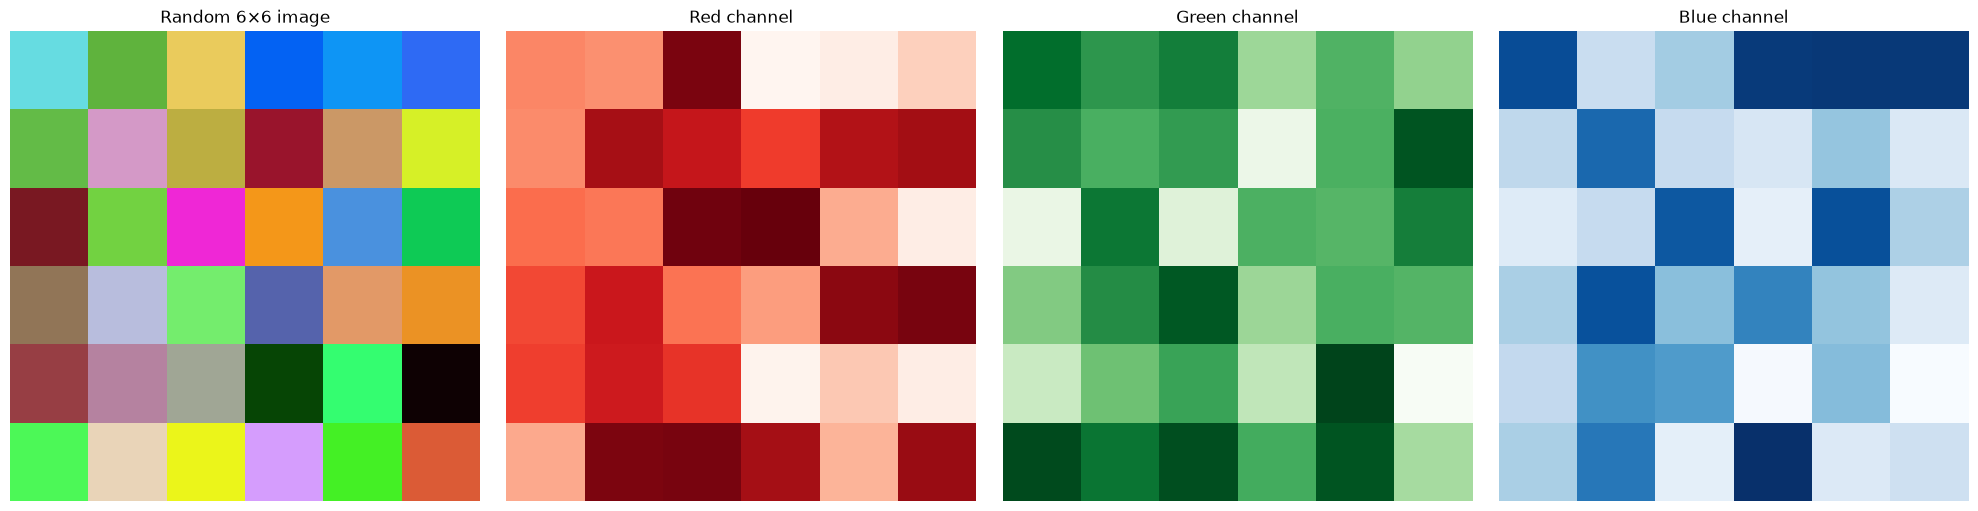

In [8]:
np.random.seed(42)   # same "random" image every run
random_img = np.random.randint(0, 256, (6, 6, 3), dtype=np.uint8)

print("shape:", random_img.shape)
print("Red channel values:\n", random_img[:, :, 0])

show_channels(random_img, "Random 6×6 image")

Look at the red-channel numbers above and compare them with the red plot: high numbers are the dark red squares, low numbers are the pale ones.

## 3. The Sobel filter

A **filter** (kernel) is a small matrix that slides over the image. The Sobel filter is a 3×3 kernel built to find edges:

- **Sobel X** compares the right column with the left column → it fires on **vertical** edges.
- **Sobel Y** (the transpose of Sobel X) compares the bottom row with the top row → it fires on **horizontal** edges.
- On a flat area the positives and negatives cancel out, so the answer is about 0.

In [9]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = sobel_x.T

print("Sobel X (highlights vertical edges):\n", sobel_x)
print("\nSobel Y (highlights horizontal edges):\n", sobel_y)

Sobel X (highlights vertical edges):
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

Sobel Y (highlights horizontal edges):
 [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


## 4. Convolution from scratch

### 4.1 Test images built from a matrix

An image is just a matrix of numbers, so we can type one in. 0 = black, 255 = white. Here is a small smiley face:

shape: (7, 8)


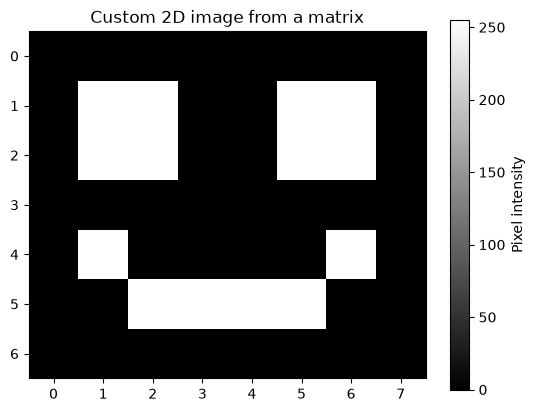

In [10]:
L = [
    [0,   0,   0,   0,   0,   0,   0,   0],
    [0, 255, 255,   0,   0, 255, 255,   0],
    [0, 255, 255,   0,   0, 255, 255,   0],
    [0,   0,   0,   0,   0,   0,   0,   0],
    [0, 255,   0,   0,   0,   0, 255,   0],
    [0,   0, 255, 255, 255, 255,   0,   0],
    [0,   0,   0,   0,   0,   0,   0,   0],
]
smiley = np.array(L, dtype=np.uint8)
print("shape:", smiley.shape)

plt.imshow(smiley, cmap="gray")
plt.title("Custom 2D image from a matrix")
plt.colorbar(label="Pixel intensity")
plt.show()

And a simpler one with a single **vertical** edge: left half black, right half white. If Sobel X works, it should light up exactly on that edge.

[[  0   0   0 255 255 255]
 [  0   0   0 255 255 255]
 [  0   0   0 255 255 255]
 [  0   0   0 255 255 255]
 [  0   0   0 255 255 255]
 [  0   0   0 255 255 255]]


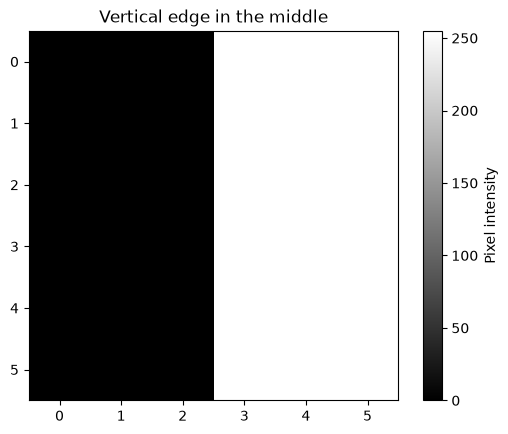

In [11]:
vertical_stripe_img = np.zeros((6, 6), dtype=np.uint8)
vertical_stripe_img[:, 3:] = 255
print(vertical_stripe_img)

plt.imshow(vertical_stripe_img, cmap="gray")
plt.title("Vertical edge in the middle")
plt.colorbar(label="Pixel intensity")
plt.show()

### 4.2 The convolution function

For every position where the kernel fits inside the image:

1. Cut out the patch under the kernel.
2. Multiply it element by element with the kernel.
3. Add everything up → one output pixel.

With stride 1, the output size is `(H + 2p − k + 1) × (W + 2p − k + 1)`, the formula from README section 7.2. With no padding (`p = 0`) the output shrinks by 2 for a 3×3 kernel; with `p = 1` (a ring of zeros around the image) it keeps the input size.

> Deep learning libraries don't flip the kernel (strictly this is *cross-correlation*), and neither do we.

In [12]:
def simple_conv(image, kernel, padding=0):
    # 2D convolution (cross-correlation), stride 1, optional zero padding.
    image = image.astype(np.float64)       # uint8 can't hold negative numbers
    if padding > 0:
        image = np.pad(image, padding, mode="constant", constant_values=0)
    kh, kw = kernel.shape
    out_h = image.shape[0] - kh + 1
    out_w = image.shape[1] - kw + 1
    output = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i:i + kh, j:j + kw]
            output[i, j] = np.sum(patch * kernel)
    return output

### 4.3 Sobel on the vertical edge

Why convert to float first? Sobel gives **negative** numbers for dark-to-bright the other way. A `uint8` image can only hold 0–255, so −255 would wrap around to 1 and the answer would be wrong.

In [13]:
result = simple_conv(vertical_stripe_img, sobel_x)
print("input 6×6 → output", result.shape)
print(result)

result_y = simple_conv(vertical_stripe_img, sobel_y)
print("\nSobel Y on the same image:\n", result_y)

input 6×6 → output (4, 4)
[[   0. 1020. 1020.    0.]
 [   0. 1020. 1020.    0.]
 [   0. 1020. 1020.    0.]
 [   0. 1020. 1020.    0.]]

Sobel Y on the same image:
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


- **Sobel X**: the two middle columns are 1020 (= 255 × 4) because that's where the dark-to-bright jump is. Everywhere else is 0.
- **Sobel Y**: all zeros. There is no horizontal edge in this image, so the horizontal detector finds nothing.

### 4.4 Sobel on the smiley

The smiley is tiny, so without padding the output would shrink from 7×8 to 5×6 and lose the outer ring of edges. Here we use `padding=1` so the output stays 7×8 and lines up with the input.

At 7×8 pixels almost every pixel touches an edge, so the picture is hard to read. We print the numbers for the real smiley, then draw the edges on a copy scaled up 6× (`np.kron` turns every pixel into a 6×6 block).

We show the absolute value, since a strong negative response is just as much an edge as a strong positive one.

output shape: (7, 8) (same as the input, thanks to padding=1)
Sobel X values (vertical edges):
 [[ 255  255 -255 -255  255  255 -255 -255]
 [ 765  765 -765 -765  765  765 -765 -765]
 [ 765  765 -765 -765  765  765 -765 -765]
 [ 510  255 -510 -255  255  510 -255 -510]
 [ 510  255 -255    0    0  255 -255 -510]
 [ 255  510  255    0    0 -255 -510 -255]
 [   0  255  255    0    0 -255 -255    0]]


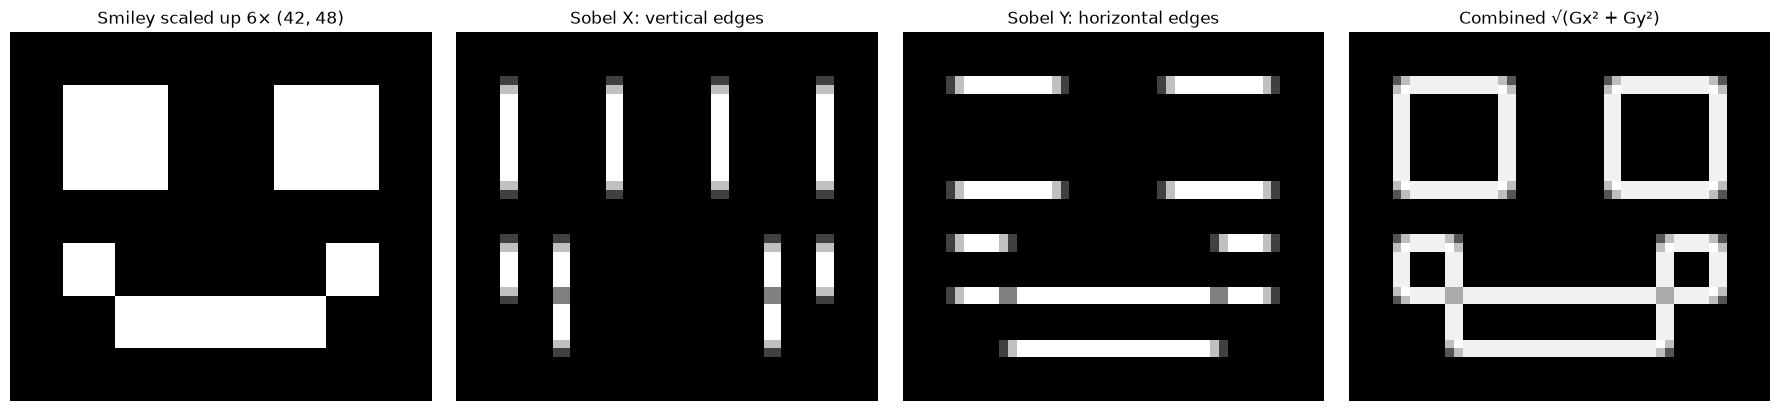

In [14]:
def show_edges(image, title, padding=1):
    gx = simple_conv(image, sobel_x, padding)
    gy = simple_conv(image, sobel_y, padding)
    magnitude = np.sqrt(gx ** 2 + gy ** 2)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    panels = [(image, title), (np.abs(gx), "Sobel X: vertical edges"),
              (np.abs(gy), "Sobel Y: horizontal edges"), (magnitude, "Combined √(Gx² + Gy²)")]
    for ax, (im, name) in zip(axes, panels):
        ax.imshow(im, cmap="gray")
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return gx, gy


# 1) The numbers, on the real 7×8 smiley
gx_smiley = simple_conv(smiley, sobel_x, padding=1)
print("output shape:", gx_smiley.shape, "(same as the input, thanks to padding=1)")
print("Sobel X values (vertical edges):\n", gx_smiley.astype(int))

# 2) The picture, on a 6× bigger copy so the edges are easy to see
smiley_big = np.kron(smiley, np.ones((6, 6), dtype=np.uint8))   # each pixel → 6×6 block
show_edges(smiley_big, f"Smiley scaled up 6× {smiley_big.shape}");

- In the big picture the eyes are squares: **Sobel X** draws only their **left and right** sides, **Sobel Y** only their **top and bottom**, and the combined map draws the full outline.
- In the numbers, the sign tells the direction: **positive** = dark → bright going right (the left side of an eye), **negative** = bright → dark (its right side). The size tells how much of the edge the kernel covers: in rows 1–2 the eye fills two of the kernel's three rows (weights 2 + 1), so the value is 255 × 3 = 765; in row 0 it only touches the bottom row (weight 1), so 255.

## 5. Real photo: our function vs OpenCV

Now the same filters on the grayscale car. OpenCV's `cv2.filter2D` does the same sliding multiply-and-add but in fast C++ code, and pads the border so the output keeps the input size. We use `cv2.CV_64F` as the output type so negative values aren't clipped.

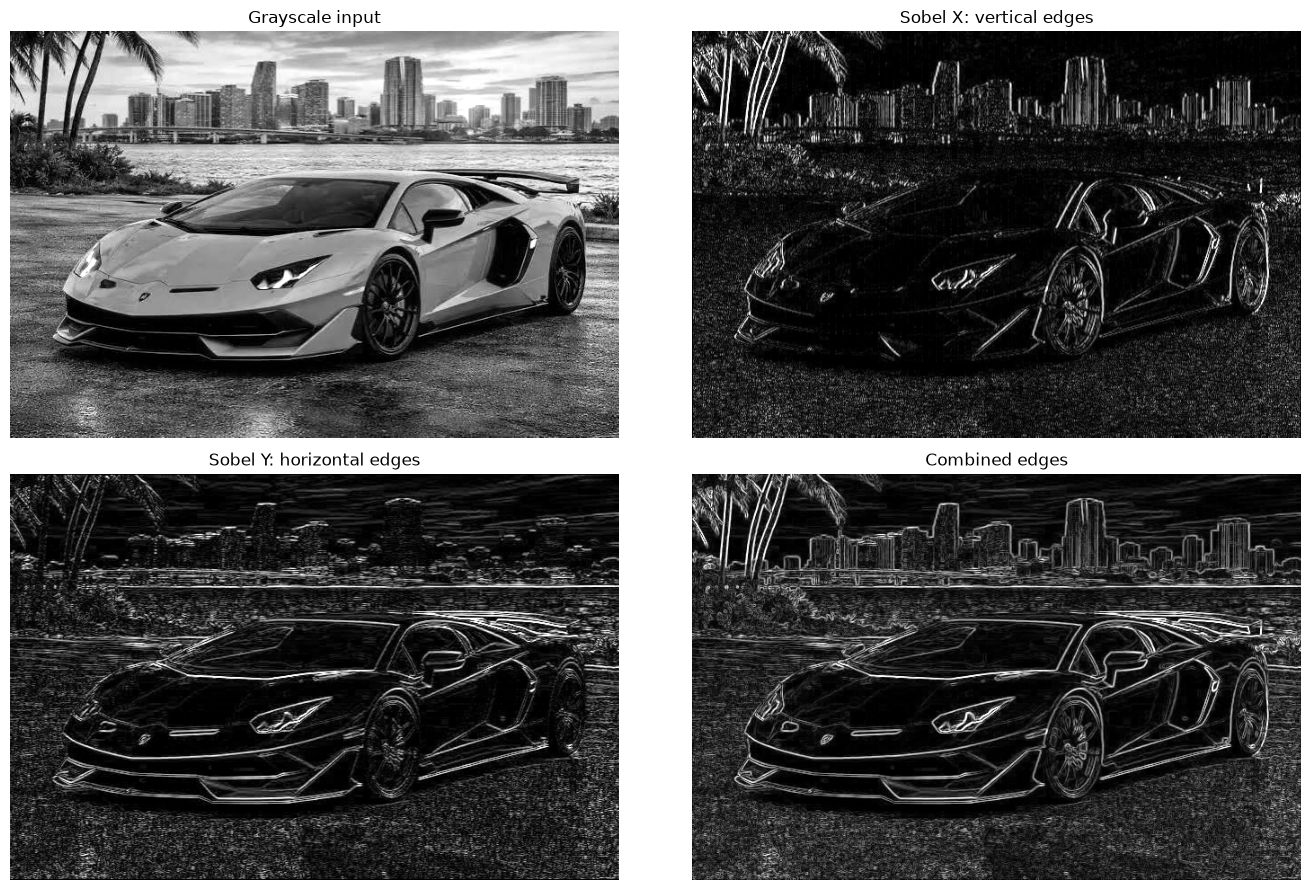

In [15]:
gx_cv = cv2.filter2D(car1_gray, cv2.CV_64F, sobel_x)
gy_cv = cv2.filter2D(car1_gray, cv2.CV_64F, sobel_y)
edges_cv = cv2.magnitude(gx_cv, gy_cv)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [(car1_gray, "Grayscale input"), (np.abs(gx_cv), "Sobel X: vertical edges"),
          (np.abs(gy_cv), "Sobel Y: horizontal edges"), (edges_cv, "Combined edges")]
for ax, (im, name) in zip(axes.flat, panels):
    ax.imshow(im, cmap="gray", vmax=np.percentile(im, 99.5))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

Check that our loop gives exactly the same numbers. Here we call `simple_conv` with no padding, so its output is 2 pixels smaller in each direction; we compare it with the inside of OpenCV's result (dropping the 1-pixel border OpenCV filled with padding).

This loop visits every pixel in Python, so it takes a second or two. That slowness is why real libraries do it in C++ or on the GPU.

In [16]:
gx_ours = simple_conv(car1_gray, sobel_x)

print("ours  :", gx_ours.shape)
print("OpenCV:", gx_cv.shape)
print("same values inside the border:", np.allclose(gx_ours, gx_cv[1:-1, 1:-1]))

ours  : (450, 676)
OpenCV: (452, 678)
same values inside the border: True


## Summary

| Idea | What we saw |
|------|-------------|
| RGB vs BGR | matplotlib reads RGB, OpenCV reads BGR; convert with `cv2.cvtColor` before `plt.imshow`. |
| Colour image | Three stacked channels (R, G, B), each a grayscale matrix of 0–255. |
| Filter / kernel | A small matrix (3×3 here) that slides over the image. |
| Sobel X / Y | Find vertical / horizontal edges; flat areas give 0. |
| Convolution | Patch × kernel, sum, move one step; output is `(H − k + 1) × (W − k + 1)` without padding. |
| Padding | A ring of zeros around the image keeps the output the same size as the input. |
| Data type | Convert to float before filtering, or negative edge values get wrapped around. |
| In a CNN | The kernel numbers aren't typed in by hand like Sobel; they are **learned** during training. |